## Data Cleaning 


In [1]:
# import libraries

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [2]:
# Paths

RAW = pathlib.Path('../data/raw/red_wine_quality.csv')
PROC = pathlib.Path('../data/processed/red_wine_cleaned.csv')
OUT = pathlib.Path('../data/outputs')
OUT.mkdir(parents=True, exist_ok=True)


In [3]:
# Load the red wine quality dataset

df = pd.read_csv(RAW)
df.head(10)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5
6,7.9,0.60,0.06,1.6,0.069,15.0,59.0,0.9964,3.30,0.46,9.4,5
7,7.3,0.65,0.00,1.2,0.065,15.0,21.0,0.9946,3.39,0.47,10.0,7
8,7.8,0.58,0.02,2.0,0.073,9.0,18.0,0.9968,3.36,0.57,9.5,7
9,7.5,0.50,0.36,6.1,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5


In [4]:
df.tail(10)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1589,6.6,0.725,0.20,7.8,0.073,29.0,79.0,0.99770,3.29,0.54,9.2,5
1590,6.3,0.550,0.15,1.8,0.077,26.0,35.0,0.99314,3.32,0.82,11.6,6
1591,5.4,0.740,0.09,1.7,0.089,16.0,26.0,0.99402,3.67,0.56,11.6,6
1592,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1593,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


In [5]:
# Shape and information

print("Shape: ", df.shape)
df.info()


Shape:  (1599, 12)
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
# Describe the dataset

df.describe(include="all")


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [7]:
# Find duplicate rows

duplicate_rows = df[df.duplicated(keep=False)]
print(f"Duplicate rows (including first copy): {len(duplicate_rows)}")
duplicate_rows.head(10)


Duplicate rows (including first copy): 460


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
9,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.9978,3.35,0.80,10.5,5
22,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.9966,3.17,0.91,9.5,5
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.9966,3.17,0.91,9.5,5
39,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.9978,3.33,0.83,10.5,5
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.9978,3.33,0.83,10.5,5
64,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.9962,3.41,0.39,10.9,5


In [8]:
# Drop duplicate rows

before = df.shape[0]
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before}, after: {df.shape[0]}, removed: {before - df.shape[0]}")
df[df.duplicated()]


Rows before: 1599, after: 1359, removed: 240


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality


In [9]:
# Missing values - this dataset ships complete

miss = df.isnull().sum().to_frame('n_missing')
miss['pct'] = miss['n_missing'] / len(df) * 100
display(miss)
print(f"Total missing cells: {int(df.isnull().sum().sum())}")


,n_missing,pct
fixed acidity,0,0.0
volatile acidity,0,0.0
citric acid,0,0.0
residual sugar,0,0.0
chlorides,0,0.0
free sulfur dioxide,0,0.0
total sulfur dioxide,0,0.0
density,0,0.0
pH,0,0.0
sulphates,0,0.0


Total missing cells: 0


quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


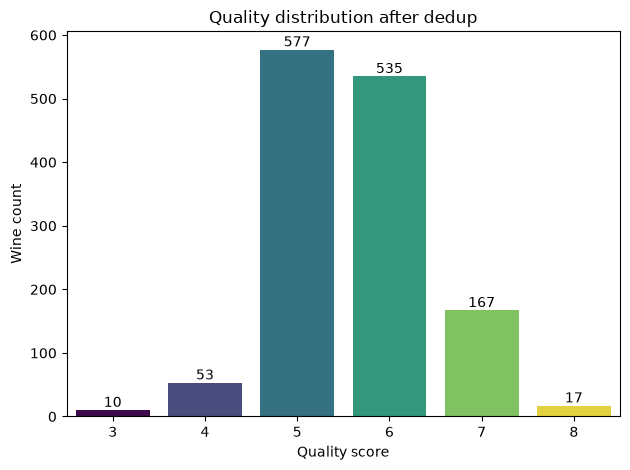

Mean quality: 5.623, std: 0.824


In [10]:
# Target distribution - quality is a score from 3 to 8

print(df['quality'].value_counts().sort_index())
ax = sns.countplot(data=df, x='quality', hue='quality', palette='viridis', legend=False)
ax.set(xlabel='Quality score', ylabel='Wine count', title='Quality distribution after dedup')
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout()
plt.show()

print(f"Mean quality: {df['quality'].mean():.3f}, std: {df['quality'].std():.3f}")


In [11]:
# Sanity checks: no negative measurements, free SO2 should not exceed total SO2

print("Negative values per column:")
print((df < 0).sum())

invalid_so2 = df[df['free sulfur dioxide'] > df['total sulfur dioxide']]
print(f"\nfree SO2 > total SO2: {len(invalid_so2)} rows")
print(f"pH range: {df['pH'].min()} - {df['pH'].max()}")


Negative values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

free SO2 > total SO2: 0 rows
pH range: 2.74 - 4.01


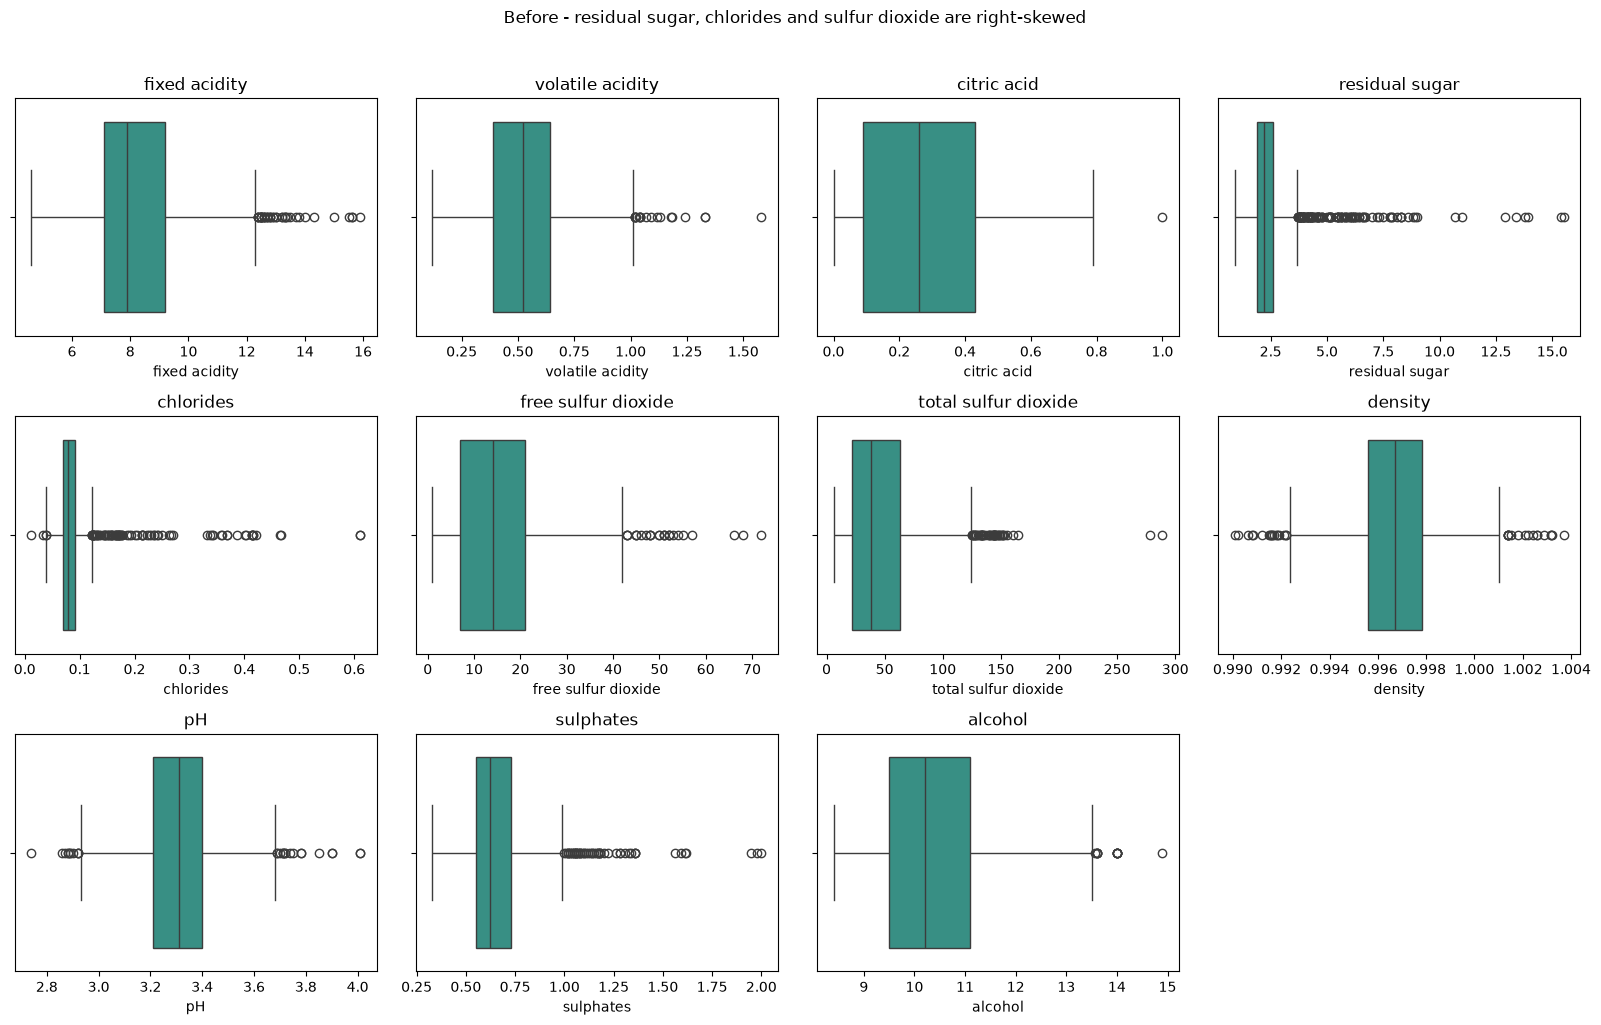

In [12]:
# Check for outliers

num_cols = [c for c in df.columns if c != 'quality']

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax, color='#2a9d8f')
    ax.set_title(col)
for ax in axes.ravel()[len(num_cols):]:
    ax.set_visible(False)
plt.suptitle('Before - residual sugar, chlorides and sulfur dioxide are right-skewed', y=1.02)
plt.tight_layout()
plt.show()


In [13]:
# Quantify: what % sits beyond 1.5 * IQR?

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    pct = ((df[col] < lo) | (df[col] > hi)).mean() * 100
    print(f"{col:24} Q1={q1:7.2f} Q3={q3:7.2f} outliers {pct:5.1f}%  hi={hi:.2f}")

# Decision: keep every row. Scaling goes inside the Pipeline in 03, fitted on train only.


fixed acidity            Q1=   7.10 Q3=   9.20 outliers   3.0%  hi=12.35
volatile acidity         Q1=   0.39 Q3=   0.64 outliers   1.4%  hi=1.02
citric acid              Q1=   0.09 Q3=   0.43 outliers   0.1%  hi=0.94
residual sugar           Q1=   1.90 Q3=   2.60 outliers   9.3%  hi=3.65
chlorides                Q1=   0.07 Q3=   0.09 outliers   6.4%  hi=0.12
free sulfur dioxide      Q1=   7.00 Q3=  21.00 outliers   1.9%  hi=42.00
total sulfur dioxide     Q1=  22.00 Q3=  63.00 outliers   3.3%  hi=124.50
density                  Q1=   1.00 Q3=   1.00 outliers   2.6%  hi=1.00
pH                       Q1=   3.21 Q3=   3.40 outliers   2.1%  hi=3.68
sulphates                Q1=   0.55 Q3=   0.73 outliers   4.0%  hi=1.00
alcohol                  Q1=   9.50 Q3=  11.10 outliers   0.9%  hi=13.50


### Correaltions


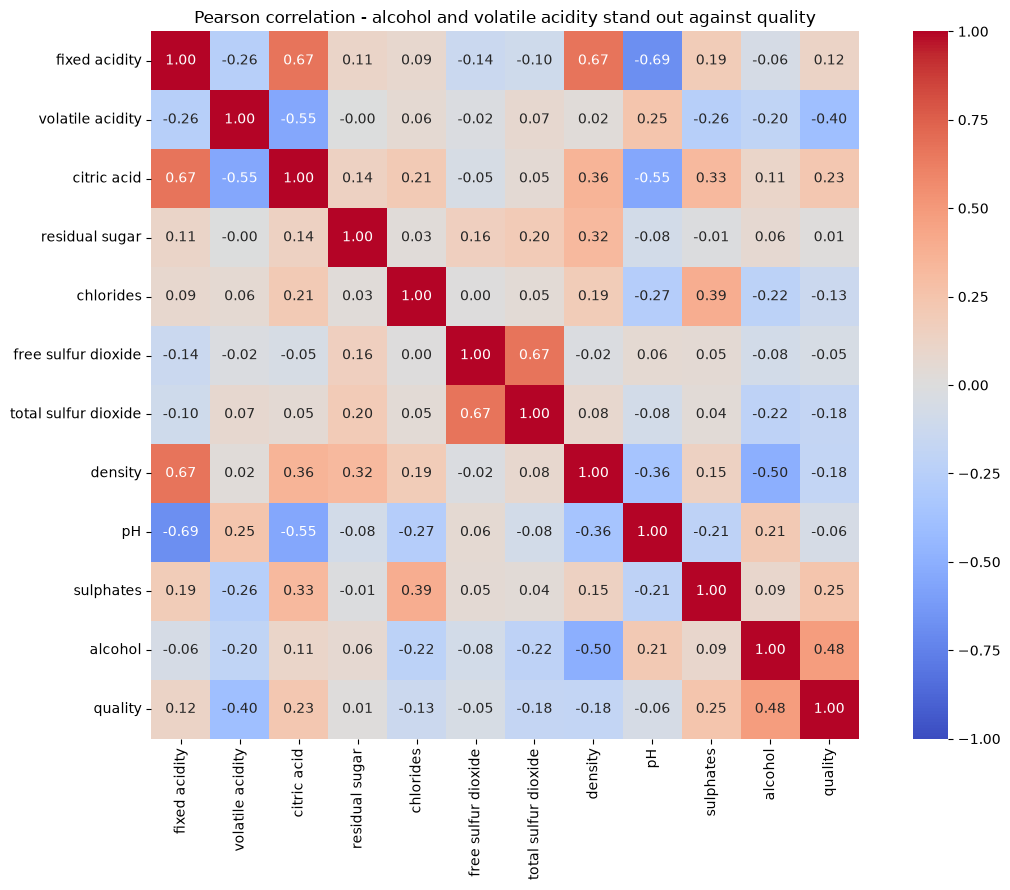

Correlation with quality:


,r
alcohol,0.480343
sulphates,0.248835
citric acid,0.228057
fixed acidity,0.119024
residual sugar,0.013640
free sulfur dioxide,-0.050463
pH,-0.055245
chlorides,-0.130988
total sulfur dioxide,-0.177855
density,-0.184252


In [14]:
# Pearson correlation - which measurements move with quality?

corr = df.corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Pearson correlation - alcohol and volatile acidity stand out against quality')
plt.tight_layout()
plt.show()

print("Correlation with quality:")
display(corr['quality'].drop('quality').sort_values(ascending=False).to_frame('r'))


In [15]:
# Variance inflation Factor

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

X_vif = add_constant(df[num_cols])
vif = pd.DataFrame({
    'feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])],
}).sort_values('VIF', ascending=False)
display(vif[vif['feature'] != 'const'])


,feature,VIF
1,fixed acidity,7.880951
8,density,6.281009
9,pH,3.397407
11,alcohol,3.140944
3,citric acid,3.124679
7,total sulfur dioxide,2.216688
6,free sulfur dioxide,1.950922
2,volatile acidity,1.777884
4,residual sugar,1.641987
5,chlorides,1.530769


In [16]:
print("Density/alcohol and free/total sulfur dioxide are correlated pairs.")
print("Decision: keep both in each pair; StandardScaler in 03 keeps distance-based models stable.")


Density/alcohol and free/total sulfur dioxide are correlated pairs.
Decision: keep both in each pair; StandardScaler in 03 keeps distance-based models stable.


In [17]:
# Save cleaned data (deduped only) - NO impute/scale yet
# SimpleImputer + StandardScaler must be fitted on the training fold only in 03.

PROC.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROC, index=False)
print(f"Saved {PROC} - {PROC.stat().st_size/1024:.1f} KB, shape {df.shape}")
display(pd.read_csv(PROC).head(2))

summary = {
    'raw_shape': [1599, 12],
    'after_dedup': list(df.shape),
    'duplicates_removed': int(before - df.shape[0]),
    'missing_cells': int(df.isnull().sum().sum()),
    'invalid_free_gt_total': int(len(invalid_so2)),
    'quality_distribution': {str(k): int(v) for k, v in df['quality'].value_counts().sort_index().items()},
    'quality_mean': round(float(df['quality'].mean()), 3),
}
import json
with open(OUT / 'cleaning_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))


Saved ../data/processed/red_wine_cleaned.csv - 77.6 KB, shape (1359, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5


{
  "raw_shape": [
    1599,
    12
  ],
  "after_dedup": [
    1359,
    12
  ],
  "duplicates_removed": 240,
  "missing_cells": 0,
  "invalid_free_gt_total": 0,
  "quality_distribution": {
    "3": 10,
    "4": 53,
    "5": 577,
    "6": 535,
    "7": 167,
    "8": 17
  },
  "quality_mean": 5.623
}
